# E3 — Comparación de los cuatro métodos Scopus

## Protocolo compartido

Misma fuente real `Data/Datos_Brutos.csv`, reglas de negocio y15 predictores.
Objetivo `nota_primer_parcial`; nota_final, pidm, periodo e índice de fila no
son entradas. Sin aumentación ni eliminación de outliers válidos.
Train1309 filas/1293 estudiantes; test202530:188 estudiantes, sin solapamiento.

Cinco folds externos canónicos por estudiante, cinco internos en cada búsqueda
y cinco internos para elegir parámetros finales. RMSE medio interno selecciona
la configuración. Cada preprocesador y modelo se ajusta solo en su fit.
La selección final se guarda antes de predecir test. Mismas funciones del tablero:
RMSE, MAE, MAPE(%) y R²; métricas sin ponderación, escala original.
Media/SD entre folds, OOF reunido y test temporal se informan por separado.

Se guardan grillas, auditorías, hashes, OOF y predicciones test. El código puede
reanudar cálculos de igual procedencia; si cambia la procedencia exige una
carpeta nueva. Pesos/estimadores quedan locales en modelos_preentrenados/scopus.
No se reemplazan los modelos del dashboard ni se reescriben informes anteriores.

In [1]:
from pathlib import Path
import sys
BOOK=Path.cwd() if (Path.cwd()/'entregable3.py').exists() else Path.cwd()/'Precalculo'
sys.path.insert(0,str(BOOK.resolve()))
import pandas as pd
from IPython.display import display
from evaluar_scopus_e3 import run,compare,ROOT

report=compare()
display(pd.DataFrame(report['test']).round(6))

          Modelo     RMSE      MAE  MAPE (%)       R²  delta_RMSE_vs_SVM  delta_RMSE_vs_XGBoost
Kernel Ridge RBF 0.904881 0.727607 28.324540 0.456316          -0.022825              -0.001393
        CatBoost 0.905669 0.731892 28.722883 0.455368          -0.022036              -0.000604
         XGBoost 0.906274 0.728918 28.404775 0.454641          -0.021432               0.000000
      SVM lineal 0.927706 0.755443 29.664556 0.428543           0.000000               0.021432
     XBART (GFR) 0.967515 0.794435 31.849667 0.378447           0.039809               0.061241
         coPILOT 0.970603 0.793968 30.540858 0.374472           0.042897               0.064329


          Modelo Referencia metrica  diferencia_ajustado_menos_referencia   IC_2.5%  IC_97.5%  p_bilateral  p_Holm_global_21  p_Holm_4_por_referencia
     XBART (GFR) SVM lineal    RMSE                              0.039809 -0.010972  0.090111      0.12166           1.00000                  0.28860
     XBART (GFR)    XGBoost    RMSE                              0.061241  0.008304  0.114403      0.02388           0.45372                  0.07164
        CatBoost SVM lineal    RMSE                             -0.022036 -0.056768  0.013772      0.21864           1.00000                  0.28860
        CatBoost    XGBoost    RMSE                             -0.000604 -0.021020  0.020201      0.95670           1.00000                  1.00000
Kernel Ridge RBF SVM lineal    RMSE                             -0.022825 -0.050050  0.003077      0.09620           1.00000                  0.28860
Kernel Ridge RBF    XGBoost    RMSE                             -0.001393 -0.024788  0.021450      0

,Modelo,RMSE,MAE,MAPE (%),R²,delta_RMSE_vs_SVM,delta_RMSE_vs_XGBoost
0,Kernel Ridge RBF,0.904881,0.727607,28.324540,0.456316,-0.022825,-0.001393
1,CatBoost,0.905669,0.731892,28.722883,0.455368,-0.022036,-0.000604
2,XGBoost,0.906274,0.728918,28.404775,0.454641,-0.021432,0.000000
3,SVM lineal,0.927706,0.755443,29.664556,0.428543,0.000000,0.021432
4,XBART (GFR),0.967515,0.794435,31.849667,0.378447,0.039809,0.061241
5,coPILOT,0.970603,0.793968,30.540858,0.374472,0.042897,0.064329


## Comparación por métrica

Cada panel tiene una escala independiente: no se mezclan las magnitudes de
RMSE, MAE, MAPE y R². Azul identifica las referencias; verde, los candidatos.

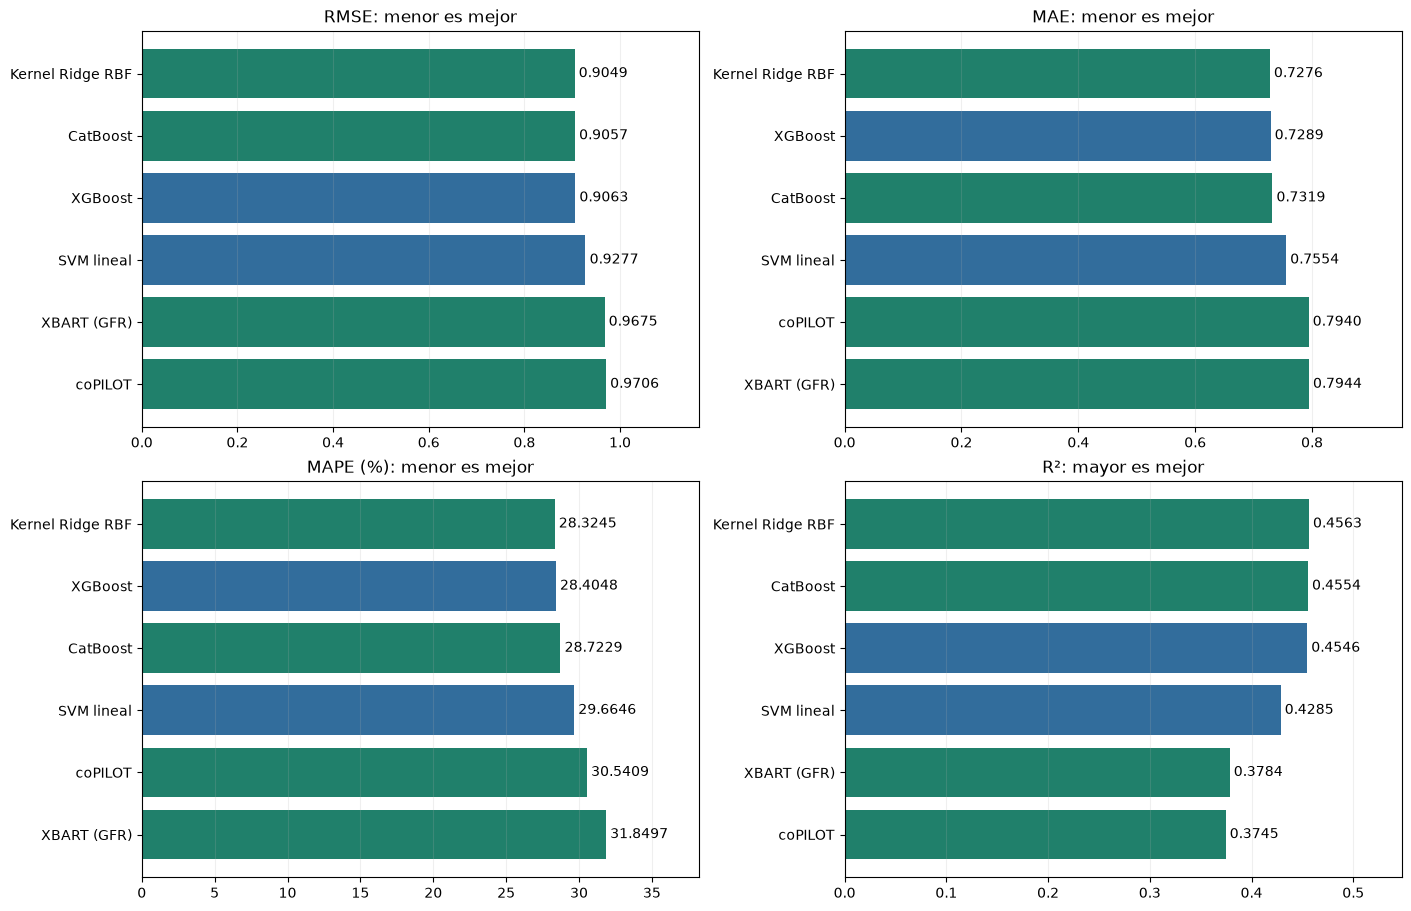

In [2]:
import matplotlib.pyplot as plt
table=pd.DataFrame(report['test'])
fig,axes=plt.subplots(2,2,figsize=(14,9),constrained_layout=True)
for ax,metric in zip(axes.flat,['RMSE','MAE','MAPE (%)','R²']):
    values=table.sort_values(metric,ascending=metric!='R²')
    bars=ax.barh(values.Modelo,values[metric],color=['#326d9c' if m in ['SVM lineal','XGBoost'] else '#20806b' for m in values.Modelo])
    ax.bar_label(bars,fmt='%.4f',padding=3)
    ax.invert_yaxis()
    ax.set_title(metric+(': mayor es mejor' if metric=='R²' else ': menor es mejor'))
    ax.margins(x=.2)
    ax.grid(axis='x',alpha=.2)
fig.savefig(ROOT/'comparacion_metricas.png',dpi=160)
plt.show()

## Diferencias pareadas y significancia

Permutación bilateral99999 y bootstrap10000 por estudiante; semilla42.
Delta=candidato−referencia: negativo favorece al candidato para RMSE,
positivo para R². Ambas métricas comparten el contraste SSE y su p-valor.
Los IC95% son marginales. Se muestran p crudo, Holm para los cuatro nuevos
frente a cada referencia y Holm global21:13 pares históricos frente a SVM,
4 nuevos frente a SVM y4 nuevos frente a XGBoost. No se cuentan RMSE/R²
como dos hipótesis independientes.

Inferencia exploratoria por reutilización del test; condicional a estos
estimadores, sin variabilidad por reentrenamiento. Un p alto no demuestra
equivalencia. Una diferencia significativa puede representar deterioro:
revisar siempre la dirección.

In [3]:
contrasts=pd.DataFrame(report['contrasts'])
display(contrasts[contrasts.metrica.eq('RMSE')].round(6))
display(contrasts[contrasts.metrica.eq('R²')].round(6))

,Modelo,Referencia,metrica,diferencia_ajustado_menos_referencia,IC_2.5%,IC_97.5%,p_bilateral,p_Holm_global_21,p_Holm_4_por_referencia
0,XBART (GFR),SVM lineal,RMSE,0.039809,-0.010972,0.090111,0.12166,1.00000,0.28860
2,XBART (GFR),XGBoost,RMSE,0.061241,0.008304,0.114403,0.02388,0.45372,0.07164
4,CatBoost,SVM lineal,RMSE,-0.022036,-0.056768,0.013772,0.21864,1.00000,0.28860
6,CatBoost,XGBoost,RMSE,-0.000604,-0.021020,0.020201,0.95670,1.00000,1.00000
8,Kernel Ridge RBF,SVM lineal,RMSE,-0.022825,-0.050050,0.003077,0.09620,1.00000,0.28860
10,Kernel Ridge RBF,XGBoost,RMSE,-0.001393,-0.024788,0.021450,0.90436,1.00000,1.00000
12,coPILOT,SVM lineal,RMSE,0.042897,-0.004053,0.088527,0.06606,1.00000,0.26424
14,coPILOT,XGBoost,RMSE,0.064329,0.023059,0.106720,0.00282,0.05640,0.01128


,Modelo,Referencia,metrica,diferencia_ajustado_menos_referencia,IC_2.5%,IC_97.5%,p_bilateral,p_Holm_global_21,p_Holm_4_por_referencia
1,XBART (GFR),SVM lineal,R²,-0.050096,-0.110238,0.014652,0.12166,1.00000,0.28860
3,XBART (GFR),XGBoost,R²,-0.076195,-0.137324,-0.011223,0.02388,0.45372,0.07164
5,CatBoost,SVM lineal,R²,0.026826,-0.016825,0.070120,0.21864,1.00000,0.28860
7,CatBoost,XGBoost,R²,0.000727,-0.023901,0.026648,0.95670,1.00000,1.00000
9,Kernel Ridge RBF,SVM lineal,R²,0.027774,-0.003740,0.062034,0.09620,1.00000,0.28860
11,Kernel Ridge RBF,XGBoost,R²,0.001675,-0.025782,0.030140,0.90436,1.00000,1.00000
13,coPILOT,SVM lineal,R²,-0.054071,-0.115371,0.004916,0.06606,1.00000,0.26424
15,coPILOT,XGBoost,R²,-0.080169,-0.137639,-0.029049,0.00282,0.05640,0.01128


## Validación externa por estudiante

In [4]:
display(pd.DataFrame([{'Modelo':r['model'],**v} for r in report['models'].values() for v in r['cv']]).round(6))

,Modelo,metrica,media_cv,sd_cv,OOF_agrupado
0,XBART (GFR),RMSE,0.882018,0.033427,0.882626
1,XBART (GFR),MAE,0.712260,0.025582,0.712248
2,XBART (GFR),MAPE (%),26.858646,1.990018,26.857500
3,XBART (GFR),R²,0.375379,0.027339,0.376296
4,CatBoost,RMSE,0.816276,0.036602,0.817092
5,CatBoost,MAE,0.646609,0.035132,0.646611
6,CatBoost,MAPE (%),24.311994,2.178608,24.311495
7,CatBoost,R²,0.463267,0.051582,0.465476
8,Kernel Ridge RBF,RMSE,0.801325,0.038516,0.802245
9,Kernel Ridge RBF,MAE,0.629252,0.034385,0.629247
